## Train a Lasso and Ridge Regression model and compare results by systematically tuning the regularization strength, assessing feature shrinkage effects, and visualizing coefficient distributions to understand model behavior.	

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv("Womens Clothing E-Commerce Reviews.csv")
df

,Unnamed: 0,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name
0,0,767,33,NaN,Absolutely wonderful - silky and sexy and comf...,4,1,0,Initmates,Intimate,Intimates
1,1,1080,34,NaN,Love this dress! it's sooo pretty. i happene...,5,1,4,General,Dresses,Dresses
2,2,1077,60,Some major design flaws,I had such high hopes for this dress and reall...,3,0,0,General,Dresses,Dresses
3,3,1049,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",5,1,0,General Petite,Bottoms,Pants
4,4,847,47,Flattering shirt,This shirt is very flattering to all due to th...,5,1,6,General,Tops,Blouses
...,...,...,...,...,...,...,...,...,...,...,...
23481,23481,1104,34,Great dress for many occasions,I was very happy to snag this dress at such a ...,5,1,0,General Petite,Dresses,Dresses
23482,23482,862,48,Wish it was made of cotton,"It reminds me of maternity clothes. soft, stre...",3,1,0,General Petite,Tops,Knits
23483,23483,1104,31,"Cute, but see through","This fit well, but the top was very see throug...",3,0,1,General Petite,Dresses,Dresses
23484,23484,1084,28,"Very cute dress, perfect for summer parties an...",I bought this dress for a wedding i have this ...,3,1,2,General,Dresses,Dresses


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23486 entries, 0 to 23485
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   Unnamed: 0               23486 non-null  int64 
 1   Clothing ID              23486 non-null  int64 
 2   Age                      23486 non-null  int64 
 3   Title                    19676 non-null  object
 4   Review Text              22641 non-null  object
 5   Rating                   23486 non-null  int64 
 6   Recommended IND          23486 non-null  int64 
 7   Positive Feedback Count  23486 non-null  int64 
 8   Division Name            23472 non-null  object
 9   Department Name          23472 non-null  object
 10  Class Name               23472 non-null  object
dtypes: int64(6), object(5)
memory usage: 2.0+ MB


In [4]:
df.isnull().sum()

Unnamed: 0                    0
Clothing ID                   0
Age                           0
Title                      3810
Review Text                 845
Rating                        0
Recommended IND               0
Positive Feedback Count       0
Division Name                14
Department Name              14
Class Name                   14
dtype: int64

In [5]:
X = df[['Age', 'Recommended IND','Positive Feedback Count']]
y = df['Rating']
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (23486, 3)
y shape: (23486,)


In [6]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Training set size:", X_train.shape)
print("Testing set size:", X_test.shape)
print()

Training set size: (18788, 3)
Testing set size: (4698, 3)



In [7]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaled Training set shape:", X_train_scaled.shape)
print("Scaled Testing set shape:", X_test_scaled.shape)

Scaled Training set shape: (18788, 3)
Scaled Testing set shape: (4698, 3)


In [8]:
from sklearn.linear_model import Ridge
from sklearn.linear_model import Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [9]:
alpha_values = [0.001, 0.01, 0.1, 1, 10, 100]

ridge_results = []
lasso_results = []

for alpha in alpha_values:

    ridge = Ridge(alpha=alpha)
    ridge.fit(X_train_scaled, y_train)
    ridge_pred = ridge.predict(X_test_scaled)

    ridge_results.append({
        'Alpha': alpha,
        'R2 Score': r2_score(y_test, ridge_pred)
    })

    lasso = Lasso(alpha=alpha, max_iter=10000)
    lasso.fit(X_train_scaled, y_train)
    lasso_pred = lasso.predict(X_test_scaled)

    lasso_results.append({
        'Alpha': alpha,
        'R2 Score': r2_score(y_test, lasso_pred)
    })

ridge_df = pd.DataFrame(ridge_results)
lasso_df = pd.DataFrame(lasso_results)

print("Ridge Results")
display(ridge_df)

print("Lasso Results")
display(lasso_df)

Ridge Results


,Alpha,R2 Score
0,0.001,0.617036
1,0.010,0.617036
2,0.100,0.617036
3,1.000,0.617038
4,10.000,0.617057
5,100.000,0.617226


Lasso Results


,Alpha,R2 Score
0,0.001,0.617088
1,0.010,0.617324
2,0.100,0.612967
3,1.000,-0.000108
4,10.000,-0.000108
5,100.000,-0.000108


In [10]:
best_ridge = ridge_df.loc[ridge_df['R2 Score'].idxmax()]
best_lasso = lasso_df.loc[lasso_df['R2 Score'].idxmax()]

print("Best Ridge Alpha:", best_ridge['Alpha'])
print("Best Ridge R2:", best_ridge['R2 Score'])

print("\nBest Lasso Alpha:", best_lasso['Alpha'])
print("Best Lasso R2:", best_lasso['R2 Score'])

Best Ridge Alpha: 100.0
Best Ridge R2: 0.6172259423209336

Best Lasso Alpha: 0.01
Best Lasso R2: 0.6173240486161748


In [11]:
# Ridge Regression model
ridge_model = Ridge(alpha=100)
ridge_model.fit(X_train_scaled, y_train)
print("Ridge Regression model trained successfully.")

Ridge Regression model trained successfully.


In [12]:
# Lasso Regression model
lasso_model = Lasso(alpha=0.01, max_iter=10000)
lasso_model.fit(X_train_scaled, y_train)
print("Lasso Regression model trained successfully.")

Lasso Regression model trained successfully.


In [13]:
## Ridge Regression Evaluation

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

y_pred_ridge = ridge_model.predict(X_test_scaled)

mae = mean_absolute_error(y_test, y_pred_ridge)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_ridge))
r2 = r2_score(y_test, y_pred_ridge)

print("Ridge Regression Evaluation")
print(f"MAE: {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R2 Score: {r2:.2f}")

Ridge Regression Evaluation
MAE: 0.57
RMSE: 0.68
R2 Score: 0.62


In [14]:
## Lasso Regression Evaluation

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

y_pred_lasso = lasso_model.predict(X_test_scaled)

mae = mean_absolute_error(y_test, y_pred_lasso)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_lasso))
r2 = r2_score(y_test, y_pred_lasso)

print("Lasso Regression Evaluation")
print(f"MAE: {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R2 Score: {r2:.2f}")

Lasso Regression Evaluation
MAE: 0.58
RMSE: 0.68
R2 Score: 0.62


In [15]:
## Ridge vs Lasso Regression Comparison
comparison_df = pd.DataFrame({
    'Model': ['Ridge Regression', 'Lasso Regression'],
    'MAE': [ mean_absolute_error(y_test, y_pred_ridge), mean_absolute_error(y_test, y_pred_lasso)],
    'RMSE': [np.sqrt(mean_squared_error(y_test, y_pred_ridge)),np.sqrt(mean_squared_error(y_test, y_pred_lasso))],
    'R2 Score': [r2_score(y_test, y_pred_ridge),r2_score(y_test, y_pred_lasso)]
})

print("Ridge vs Lasso Regression Comparison")
comparison_df

Ridge vs Lasso Regression Comparison


,Model,MAE,RMSE,R2 Score
0,Ridge Regression,0.574708,0.680995,0.617226
1,Lasso Regression,0.575664,0.680908,0.617324


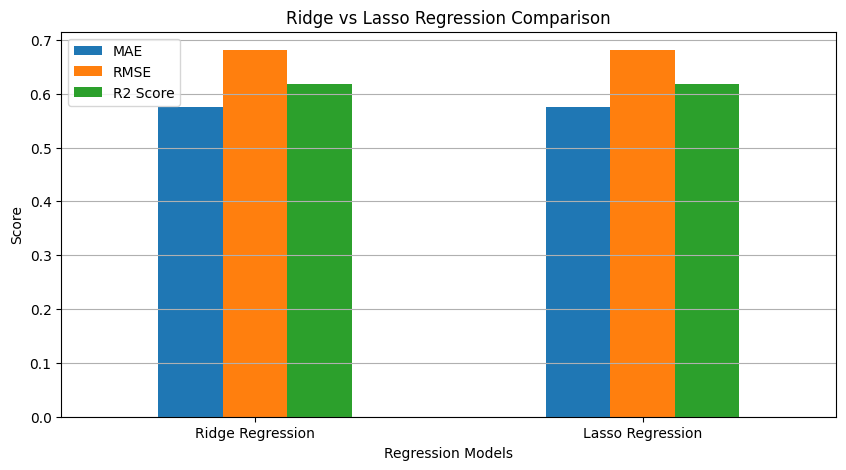

In [16]:
comparison_df.set_index('Model')[['MAE', 'RMSE', 'R2 Score']].plot(kind='bar',figsize=(10, 5))

plt.title("Ridge vs Lasso Regression Comparison")
plt.ylabel("Score")
plt.xlabel("Regression Models")
plt.xticks(rotation=0)
plt.legend()
plt.grid(axis='y')
plt.show()

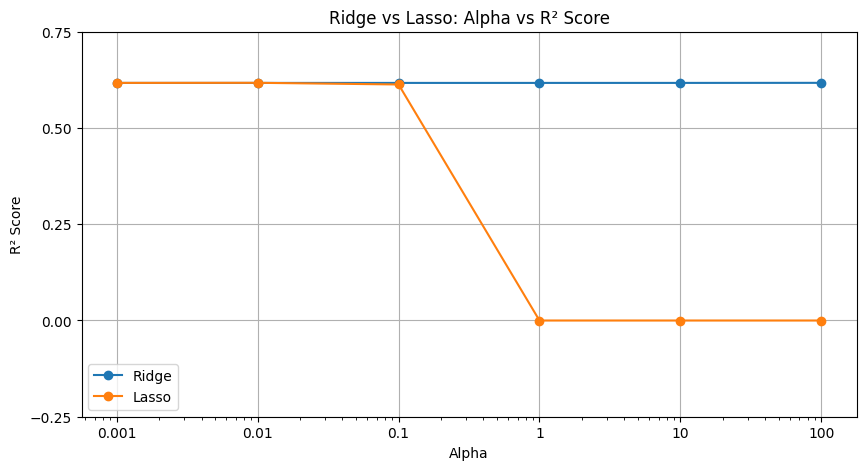

In [17]:
plt.figure(figsize=(10, 5))

plt.plot(ridge_df['Alpha'], ridge_df['R2 Score'],marker='o', label='Ridge')
plt.plot(lasso_df['Alpha'], lasso_df['R2 Score'],marker='o', label='Lasso')

plt.xscale('log')

plt.xticks(alpha_values, ['0.001', '0.01', '0.1', '1', '10', '100'])
plt.yticks(np.arange(-0.25, 0.76, 0.25))

plt.xlabel("Alpha")
plt.ylabel("R² Score")
plt.title("Ridge vs Lasso: Alpha vs R² Score")

plt.legend()
plt.grid(True)
plt.show()

In [18]:
coefficient_results = []

for alpha in alpha_values:
    # Usually does not make coefficients exactly zero.
    ridge = Ridge(alpha=alpha)
    ridge.fit(X_train_scaled, y_train)
    #Can make some coefficients exactly zero.
    lasso = Lasso(alpha=alpha, max_iter=10000)
    lasso.fit(X_train_scaled, y_train)

    for i, feature in enumerate(X.columns):

        coefficient_results.append({
            'Alpha': alpha,
            'Feature': feature,
            'Ridge Coefficient': ridge.coef_[i],
            'Lasso Coefficient': lasso.coef_[i]
        })

coef_df = pd.DataFrame(coefficient_results)
coef_df

,Alpha,Feature,Ridge Coefficient,Lasso Coefficient
0,0.001,Age,0.005374,0.004364
1,0.001,Recommended IND,0.882273,0.881368
2,0.001,Positive Feedback Count,-0.010809,-0.009829
3,0.010,Age,0.005374,0.000000
4,0.010,Recommended IND,0.882272,0.873079
5,0.010,Positive Feedback Count,-0.010809,-0.001212
6,0.100,Age,0.005374,0.000000
7,0.100,Recommended IND,0.882268,0.783161
8,0.100,Positive Feedback Count,-0.010809,-0.000000
9,1.000,Age,0.005375,0.000000


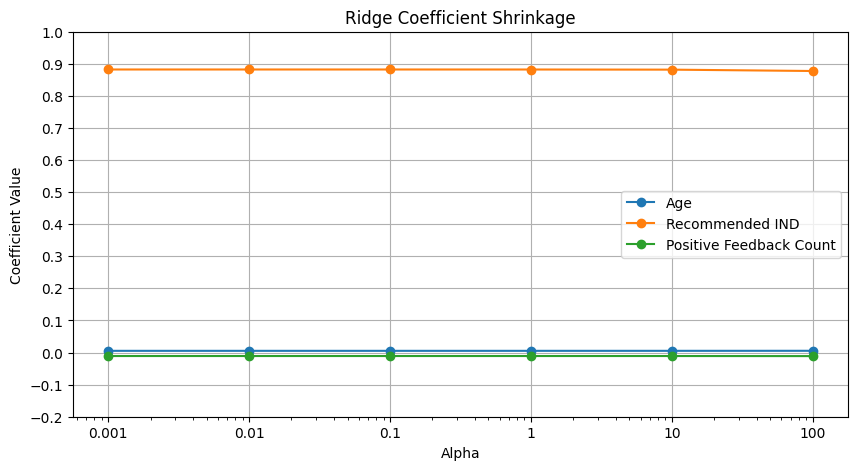

In [19]:
# Ridge Coefficient Shrinkage

plt.figure(figsize=(10, 5))

for feature in X.columns:

    temp = coef_df[coef_df['Feature'] == feature]
    plt.plot(temp['Alpha'], temp['Ridge Coefficient'],marker='o', label=feature)

plt.xscale('log')

plt.xticks(alpha_values, ['0.001', '0.01', '0.1', '1', '10', '100'])

plt.yticks(np.arange(-0.2, 1.1, 0.1))

plt.xlabel('Alpha')
plt.ylabel('Coefficient Value')

plt.title('Ridge Coefficient Shrinkage')

plt.legend()
plt.grid(True)
plt.show()

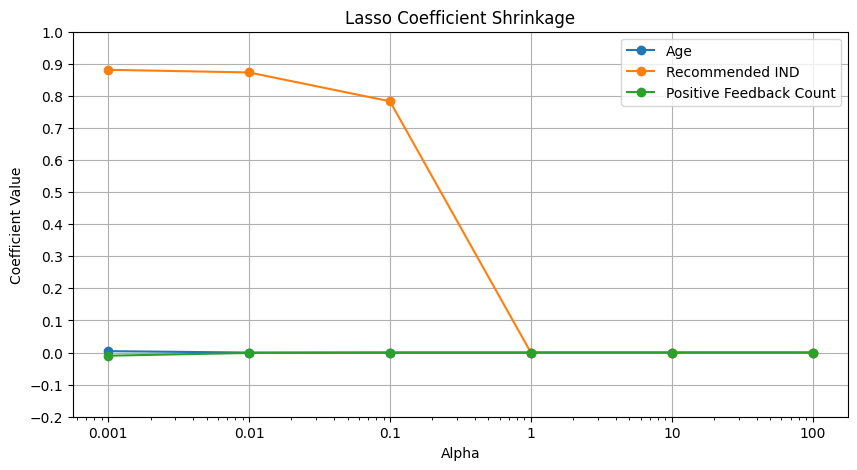

In [20]:
#Visualize Lasso Coefficient Shrinkage
plt.figure(figsize=(10, 5))

for feature in X.columns:

    temp = coef_df[coef_df['Feature'] == feature]
    plt.plot(temp['Alpha'], temp['Lasso Coefficient'],marker='o', label=feature)

plt.xscale('log')
plt.xticks(alpha_values, ['0.001', '0.01', '0.1', '1', '10', '100'])
plt.yticks(np.arange(-0.2, 1.1, 0.1))

plt.xlabel('Alpha')
plt.ylabel('Coefficient Value')
plt.title('Lasso Coefficient Shrinkage')

plt.legend()
plt.grid(True)
plt.show()

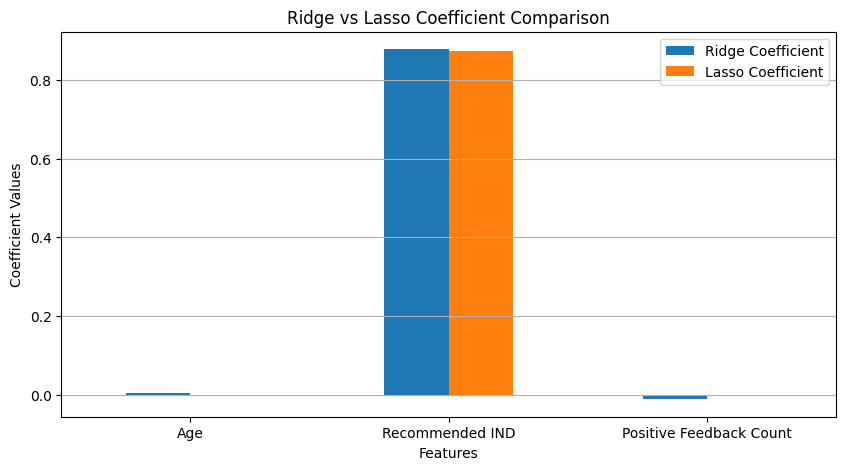

In [21]:
# Ridge vs Lasso Coefficient Comparison

coefficient_comparison = pd.DataFrame({
    'Feature': X.columns,
    'Ridge Coefficient': ridge_model.coef_,
    'Lasso Coefficient': lasso_model.coef_
})

coefficient_comparison.set_index('Feature').plot(
    kind='bar',
    figsize=(10, 5)
)

plt.xlabel('Features')
plt.ylabel('Coefficient Values')
plt.title('Ridge vs Lasso Coefficient Comparison')

plt.xticks(rotation=0)
plt.legend()
plt.grid(axis='y')
plt.show()

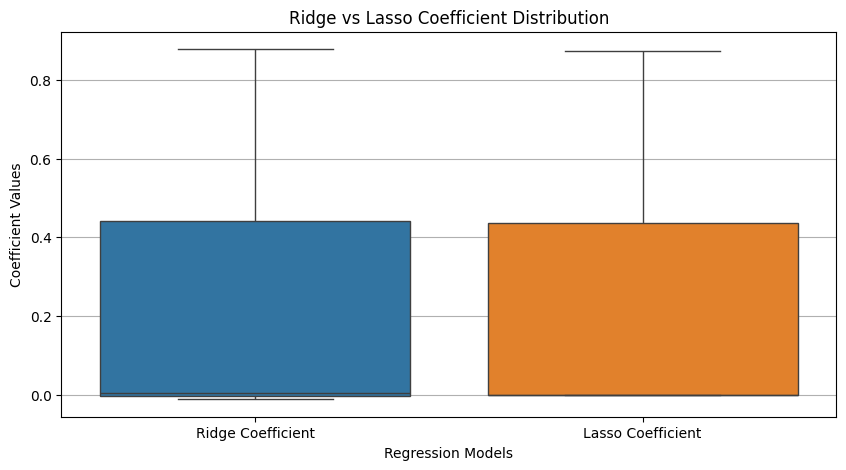

In [22]:
# Coefficient Distribution

plt.figure(figsize=(10, 5))

sns.boxplot(
    data=coefficient_comparison[
        ['Ridge Coefficient', 'Lasso Coefficient']
    ]
)

plt.title('Ridge vs Lasso Coefficient Distribution')
plt.xlabel('Regression Models')
plt.ylabel('Coefficient Values')

plt.grid(axis='y')
plt.show()

In [ ]:
# Coefficient Heatmap

plt.figure(figsize=(8, 5))

sns.heatmap(
    coefficient_comparison.set_index('Feature'),
    annot=True,
    cmap='coolwarm',
    fmt='.4f'
)

plt.title('Ridge vs Lasso Coefficient Heatmap')
plt.show()